In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df = pd.read_csv('/kaggle/input/datasets/pooriamst/metro-interstate-traffic-volume/Metro_Interstate_Traffic_Volume.csv')

In [4]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [5]:
df.shape

(48204, 9)

In [10]:
df.isnull().sum()

holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

In [9]:

categorical_cols = [
    "holiday",
    "weather_main",
    "weather_description"
]

for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(10))
df["date_time"] = pd.to_datetime(df["date_time"])
print("\nDate range:")
print("Start:", df["date_time"].min())
print("End:", df["date_time"].max())
print("\nHighest rainfall values:")
print(df["rain_1h"].nlargest(10).to_list())
print("\nTraffic volume statistics:")
print(df["traffic_volume"].describe())

Missing values:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Duplicate rows: 17

holiday: 11 unique values
holiday
Labor Day                    7
Christmas Day                6
Thanksgiving Day             6
Martin Luther King Jr Day    6
New Years Day                6
Veterans Day                 5
Columbus Day                 5
Memorial Day                 5
Washingtons Birthday         5
State Fair                   5
Name: count, dtype: int64

weather_main: 11 unique values
weather_main
Clouds          15164
Clear           13391
Mist             5950
Rain             5672
Snow             2876
Drizzle          1821
Haze             1360
Thunderstorm     1034
Fog               912
Smoke              20
Name: count, dtype: int64

weather_description: 38 uni

In [11]:
df["holiday"] = df["holiday"].fillna("None")
print(df["holiday"].isnull().sum())

0


In [12]:
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Shape after removing duplicates: (48187, 9)
Duplicates remaining: 0


In [13]:
df.nlargest(10, "rain_1h")[
    ["date_time", "temp", "rain_1h",
     "snow_1h", "weather_main",
     "weather_description", "traffic_volume"]
]

,date_time,temp,rain_1h,snow_1h,weather_main,weather_description,traffic_volume
24872,2016-07-11 17:00:00,302.11,9831.30,0.0,Rain,very heavy rain,5535
8247,2013-08-07 02:00:00,289.10,55.63,0.0,Rain,very heavy rain,315
7179,2013-06-24 11:00:00,295.82,44.45,0.0,Rain,very heavy rain,4802
25779,2016-08-16 17:00:00,297.71,31.75,0.0,Rain,very heavy rain,4913
10806,2013-12-19 23:00:00,264.50,28.70,0.0,Rain,very heavy rain,1190
10807,2013-12-19 23:00:00,264.50,28.70,0.0,Snow,light snow,1190
16504,2015-07-13 00:00:00,292.02,27.57,0.0,Rain,very heavy rain,492
16505,2015-07-13 00:00:00,292.02,27.57,0.0,Thunderstorm,proximity thunderstorm,492
16506,2015-07-13 00:00:00,292.02,27.57,0.0,Mist,mist,492
17437,2015-08-16 21:00:00,294.49,25.46,0.0,Rain,very heavy rain,2118


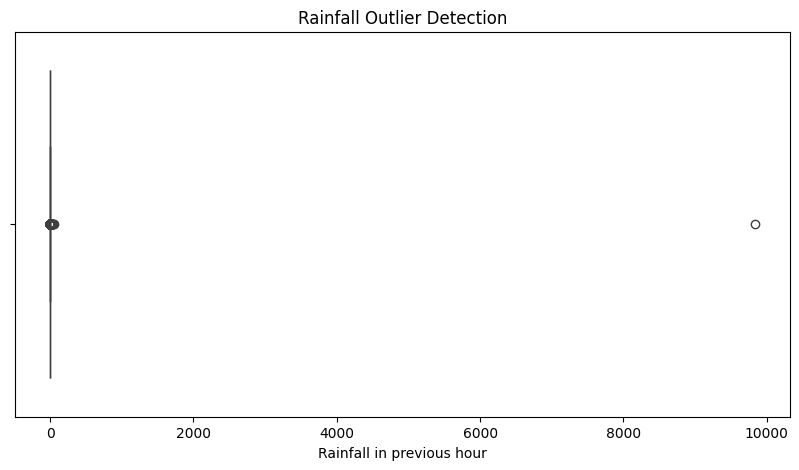

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["rain_1h"])
plt.title("Rainfall Outlier Detection")
plt.xlabel("Rainfall in previous hour")
plt.show()

In [15]:
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["year"] = df["date_time"].dt.year
df["is_weekend"] = (
    df["day_of_week"].isin([5, 6])
).astype(int)
print(df[[
    "date_time",
    "hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend"
]].head())

            date_time  hour  day_of_week  month  year  is_weekend
0 2012-10-02 09:00:00     9            1     10  2012           0
1 2012-10-02 10:00:00    10            1     10  2012           0
2 2012-10-02 11:00:00    11            1     10  2012           0
3 2012-10-02 12:00:00    12            1     10  2012           0
4 2012-10-02 13:00:00    13            1     10  2012           0


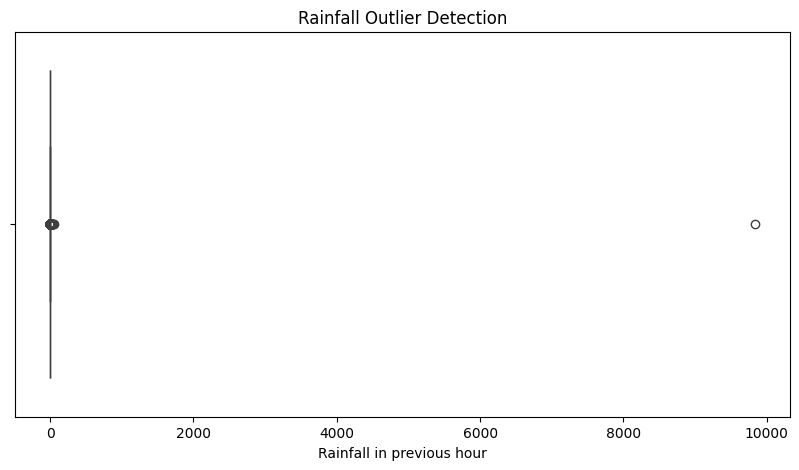

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["rain_1h"])

plt.title("Rainfall Outlier Detection")
plt.xlabel("Rainfall in previous hour")
plt.show()

In [27]:
df["date_time"] = pd.to_datetime(
    df["date_time"],
    errors="coerce"
)
print(df["date_time"].dtype)

datetime64[ns]


In [28]:
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["year"] = df["date_time"].dt.year
df["is_weekend"] = (
    df["day_of_week"].isin([5, 6])
).astype(int)
print(df[[
    "date_time",
    "hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend"
]].head())

            date_time  hour  day_of_week  month  year  is_weekend
0 2012-10-02 09:00:00     9            1     10  2012           0
1 2012-10-02 10:00:00    10            1     10  2012           0
2 2012-10-02 11:00:00    11            1     10  2012           0
3 2012-10-02 12:00:00    12            1     10  2012           0
4 2012-10-02 13:00:00    13            1     10  2012           0


In [29]:
print(df[[
    "date_time",
    "hour",
    "day_of_week",
    "month"
]].isnull().sum())

date_time      0
hour           0
day_of_week    0
month          0
dtype: int64


In [30]:
numeric_features = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "hour",
    "day_of_week",
    "month",
    "year",
    "is_weekend"
]
categorical_features = [
    "holiday",
    "weather_main",
    "weather_description"
]
X = df[numeric_features + categorical_features]
y = df["traffic_volume"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (48204, 12)
y shape: (48204,)


In [31]:
df = df.sort_values("date_time").reset_index(drop=True)
X = df[numeric_features + categorical_features]
y = df["traffic_volume"]
split_index = int(len(df) * 0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Training period:",
      df["date_time"].iloc[0],
      "to",
      df["date_time"].iloc[split_index - 1])
print("Testing period:",
      df["date_time"].iloc[split_index],
      "to",
      df["date_time"].iloc[-1])

Training: (38563, 12)
Testing: (9641, 12)
Training period: 2012-10-02 09:00:00 to 2017-11-01 20:00:00
Testing period: 2017-11-01 20:00:00 to 2018-09-30 23:00:00


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [33]:
from sklearn.linear_model import LinearRegression
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])
lr_model.fit(X_train, y_train)
print("Linear Regression training completed!")

Linear Regression training completed!


In [34]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
y_pred = lr_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1539.118555251109
RMSE: 1762.6196185704935
R2 Score: 0.19755909437660724


In [37]:
baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)
print("Baseline MAE:",
      mean_absolute_error(y_test, baseline_pred))
print("Baseline RMSE:",
      np.sqrt(mean_squared_error(y_test, baseline_pred)))
print("Baseline R2:",
      r2_score(y_test, baseline_pred))

Baseline MAE: 1722.5663962071417
Baseline RMSE: 1967.6771176292893
Baseline R2: -8.129152512248439e-06


In [39]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone
dt_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("R2 Score:", r2_score(y_test, y_pred_dt))

MAE: 335.93712293105204
RMSE: 592.8466518971104
R2 Score: 0.909222001486717


In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
rf_reg_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_train, y_train)
y_pred_rf = rf_reg_model.predict(X_test)
print("Random Forest training completed!")

Random Forest training completed!


In [41]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np
predictions = {
    "Linear Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}
results = []
for model_name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1539.1186,1762.6196,0.1976
1,Decision Tree,335.9371,592.8467,0.9092
2,Random Forest,296.2426,526.3683,0.9284


In [42]:
results_df["Best Model"] = (
    results_df["Model"] == "Random Forest"
)
display(results_df.round(4))
results_df.to_csv(
    "roadsense_regression_results.csv",
    index=False
)

,Model,MAE,RMSE,R2 Score,Best Model
0,Linear Regression,1539.1186,1762.6196,0.1976,False
1,Decision Tree,335.9371,592.8467,0.9092,False
2,Random Forest,296.2426,526.3683,0.9284,True


In [43]:
import joblib
joblib.dump(
    rf_reg_model,
    "roadsense_traffic_random_forest.pkl"
)
print("Traffic regression model saved!")

Traffic regression model saved!
